# 03 — Exploratory Data Analysis

**Stage 3 of the Tier A pipeline.** Hypothesis-driven: one section per branch of the Stage 0 issue
tree (`01` §0.4). Every chart carries an **Action Title** and a written **So What** and
**Implication** beneath it. Branch F (foreseeability) is `05`'s job and is not previewed here.

| Branch | Question | Exhibit |
|---|---|---|
| **A. The record** | What can this file say about time — and what drove the post-2010 decline in it? | ex01 |
| **B. Titles** | How unequal is a release's outcome, and is it changing? | ex02 |
| **C. Owners** | Who captures the value — and do platform holders' own games out-sell everyone else's? | ex03 |
| **D. Regions** | Where is the value, and how different is regional taste? | ex04, ex05 |
| **E. Products** | Does *what* you make separate winners the way *who* makes it does? | ex06 |

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd()
while not (ROOT / "archive" / "vgsales.csv").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
ARCHIVE = ROOT / "archive"
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
REPORTS, FIGS, MODELS = ROOT / "reports", ROOT / "reports" / "figures", ROOT / "models"
for p in (RAW, PROC, REPORTS, FIGS, MODELS):
    p.mkdir(parents=True, exist_ok=True)

KF_PATH = REPORTS / "_key_figures.json"


def _plain(v):
    if hasattr(v, "item"):
        return v.item()
    if isinstance(v, (list, tuple)):
        return [_plain(x) for x in v]
    return v


def kf_update(**kw):
    """Append to reports/_key_figures.json — the only place the report reads numbers from."""
    kf = json.loads(KF_PATH.read_text()) if KF_PATH.exists() else {}
    kf.update({k: _plain(v) for k, v in kw.items()})
    KF_PATH.write_text(json.dumps(kf, indent=1, sort_keys=True))
    print(f"  _key_figures.json <- {', '.join(kw)}  ({len(kf)} figures total)")

# ---------------------------------------------------------------------------------------------
# DESIGN.md palette, defined inline (no local module imports — a fresh clone must run as-is).
#
# Validated with the dataviz skill's checker rather than eyeballed:
#   node scripts/validate_palette.js "#2251FF,#008A7E,#C1841C" --mode light
#     PASS lightness | PASS chroma floor | PASS CVD separation (worst adjacent dE 12.5 protan)
#     PASS normal-vision separation (21.1) | PASS contrast vs surface
# DESIGN.md's Teal #00857C FAILS the chroma floor (C = 0.097 < 0.10, reads as grey), so it is
# nudged to #008A7E — same hue, +0.005 chroma. Cyan and Slate are not used as identities.
# Grey is context ink only; Navy is text ink only; neither is ever a series colour.
# ---------------------------------------------------------------------------------------------
NAVY, BLUE, TEAL, AMBER = "#051C2C", "#2251FF", "#008A7E", "#C1841C"
SLATE, GREY, GRID, LIGHT = "#7F93A6", "#9FADB8", "#E9ECEF", "#D5DCE2"

# Semantic mapping, fixed once and used in every notebook:
C_FOCUS = BLUE        # the emphasis story: hits, first-party, Japan, the model
C_SECOND = TEAL       # the second series: Europe, the tail, third-party comparison
C_REF = AMBER         # reference lines, censored years, baselines, Other region
C_CONTEXT = GREY      # non-highlighted context (incl. North America in regional mixes)
REGION_COLORS = {"NA": GREY, "EU": TEAL, "JP": BLUE, "Other": AMBER}


def apply_style():
    mpl.rcParams.update({
        "figure.dpi": 130, "savefig.dpi": 130, "figure.facecolor": "white",
        "axes.facecolor": "white", "savefig.facecolor": "white",
        "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
        "font.size": 9, "text.color": NAVY,
        "axes.titlelocation": "left", "axes.titlesize": 10.5, "axes.titleweight": "bold",
        "axes.titlecolor": NAVY, "axes.titlepad": 10,
        "axes.labelsize": 9, "axes.labelcolor": SLATE, "axes.edgecolor": GREY,
        "axes.spines.top": False, "axes.spines.right": False, "axes.linewidth": 0.8,
        "xtick.color": SLATE, "ytick.color": SLATE, "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
        "grid.color": GRID, "grid.linewidth": 0.8, "axes.grid": True, "axes.grid.axis": "y",
        "axes.axisbelow": True,
        "legend.frameon": False, "legend.fontsize": 8.5,
        "lines.linewidth": 2.0, "lines.markersize": 8,
    })


apply_style()
PCT = PercentFormatter(1.0)
SOURCE = "vgsales.csv (vgchartz.com scrape, snapshot c. late 2016)"


def finish(fig, note=""):
    """Every exhibit carries its source line — STRUCTURE.md Step 7.3."""
    fig.text(0.005, -0.015, f"Source: {SOURCE}" + (f" · {note}" if note else ""),
             fontsize=7, color=SLATE, ha="left", va="top")


def suptitle(fig, text, y=1.04):
    fig.suptitle(text, x=0.005, ha="left", fontsize=11.5, fontweight="bold", color=NAVY, y=y)


def save(fig, name):
    fig.savefig(FIGS / name, bbox_inches="tight", facecolor="white")
    print(f"  saved reports/figures/{name}")


df = pd.read_parquet(PROC / "vg_rows.parquet")
titles = pd.read_parquet(PROC / "vg_titles.parquet")
REGIONS = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]
ERAS = ["1980–94", "1995–2000", "2001–05", "2006–10", "2011–16"]
dt = df[df.Year.notna()].copy()           # time views only
dt["Year"] = dt.Year.astype(int)
print(f"{len(df):,} rows · {len(dt):,} with a usable year · {len(titles):,} titles")


def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    return float((2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum()))


def top_share(x, q=0.10):
    s = np.sort(np.asarray(x, dtype=float))[::-1]
    return float(s[: max(1, int(len(s) * q))].sum() / s.sum())


# Wherever 2015–16 (censored) are excluded, the last era is really 2011–14 — label it honestly.
def relabel(ix):
    return [str(e).replace("2011–16", "2011–14") for e in ix]

16,595 rows · 16,435 with a usable year · 11,493 titles


## 3.1 Branch A — the record

**Hypothesis (Stage 0):** the drop from ~600 M units/yr (2010) to 71 M (2016) is mostly a coverage
artifact, not a market collapse. The data review asserted this; it did not decompose it.

Two different mechanisms could each produce a falling line, and they imply different things:

1. **Right-censoring.** Lifetime sales are measured at a late-2016 snapshot, so a 2016 release has
   had months on sale and a 2015 release one to two years. That depresses *units per release* for
   the last two years regardless of demand.
2. **Composition.** If a whole tier of releases stops being made (or stops being catalogued), the
   *count* of releases falls even if the surviving releases sell as well as before.

In [2]:
P1, P2 = (2008, 2010), (2012, 2014)       # peak vs post-peak, both before the censored years
CASUAL_PLATS = ["DS", "Wii"]

yr = dt[dt.Year.between(1995, 2016)]
by = yr.groupby("Year").agg(
    releases=("Name", "size"),
    ds_wii=("Platform", lambda s: s.isin(CASUAL_PLATS).sum()),
    units=("Global_Sales", "sum"),
    hit_units=("Global_Sales", lambda s: s[s >= 1].sum()),
    hits=("is_hit", "sum"),
    median=("Global_Sales", "median"),
)
by["tail_units"] = by.units - by.hit_units
by["hit_rate"] = by.hits / by.releases


def per_year(col, period):
    return by.loc[period[0]:period[1], col].mean()


dec = pd.DataFrame({c: [per_year(c, P1), per_year(c, P2)] for c in
                    ["releases", "ds_wii", "units", "hit_units", "tail_units", "hits", "hit_rate", "median"]},
                   index=["2008–10 avg", "2012–14 avg"]).T
dec["change"] = dec.iloc[:, 1] / dec.iloc[:, 0] - 1
print(dec.round(3).to_string())

lost_releases = dec.loc["releases"].iloc[0] - dec.loc["releases"].iloc[1]
lost_dswii = dec.loc["ds_wii"].iloc[0] - dec.loc["ds_wii"].iloc[1]
print(f"\nreleases lost per year: {lost_releases:.0f} · of which DS + Wii: {lost_dswii:.0f} "
      f"({lost_dswii / lost_releases:.0%})")
print(f"units lost per year   : {dec.loc['units'].iloc[0] - dec.loc['units'].iloc[1]:.0f} M")
print(f"\nmedian units per release by year (censoring check):")
print(by.loc[2010:2016, ["releases", "median", "hit_rate"]].round(3).to_string())

            2008–10 avg  2012–14 avg  change
releases       1383.000      599.000  -0.567
ds_wii          697.667       29.000  -0.958
units           653.870      358.173  -0.452
hit_units       384.297      240.460  -0.374
tail_units      269.573      117.713  -0.563
hits            137.333       85.333  -0.379
hit_rate          0.099        0.144   0.448
median            0.160        0.177   0.104

releases lost per year: 784 · of which DS + Wii: 669 (85%)
units lost per year   : 296 M

median units per release by year (censoring check):
      releases  median  hit_rate
Year                            
2010      1272    0.15     0.100
2011      1156    0.14     0.096
2012       665    0.18     0.123
2013       550    0.19     0.165
2014       582    0.16     0.143
2015       614    0.09     0.101
2016       344    0.05     0.044


### Exhibit 1 — The post-2010 slump is two retiring platforms and two censored years, not vanishing hits

  saved reports/figures/ex01_record.png


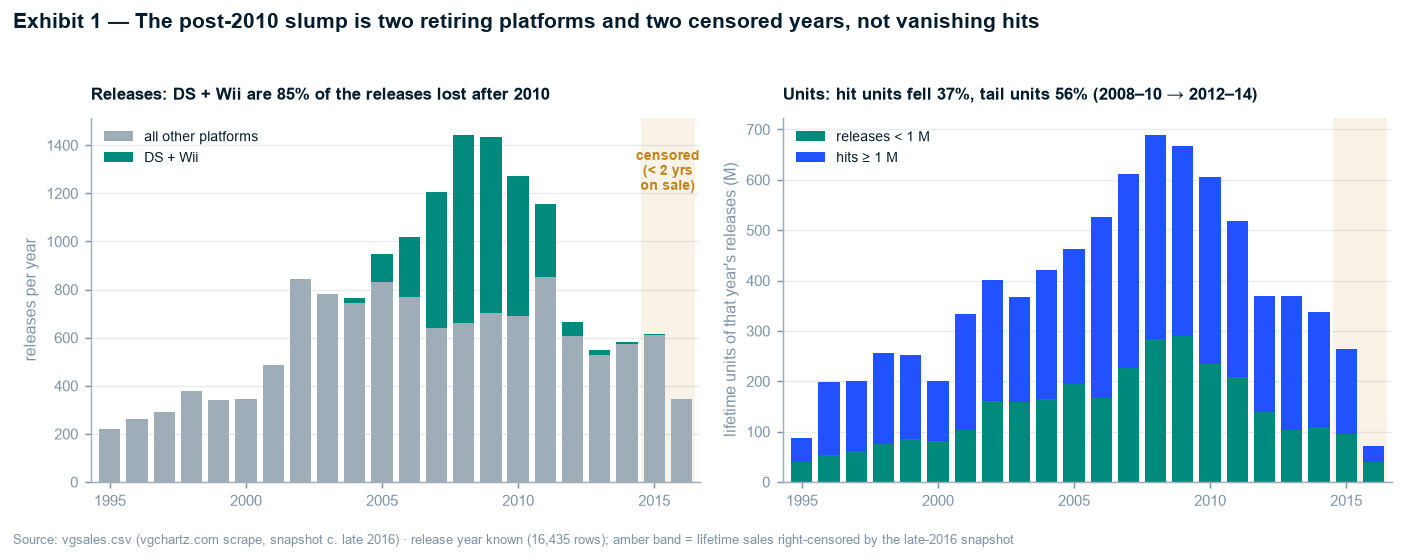

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 3.8))
x = by.index.to_numpy()
other = (by.releases - by.ds_wii).to_numpy()

for ax in (ax1, ax2):
    ax.axvspan(2014.5, 2016.5, color=AMBER, alpha=0.10, lw=0)
ax1.bar(x, other, color=GREY, width=0.78, label="all other platforms")
ax1.bar(x, by.ds_wii, bottom=other, color=TEAL, width=0.78, label="DS + Wii")
ax1.set_ylabel("releases per year")
ax1.set_title(f"Releases: DS + Wii are {lost_dswii / lost_releases:.0%} of the releases lost after 2010",
              fontsize=9.5)
ax1.legend(loc="upper left", fontsize=8)
ax1.text(2015.5, by.releases.max() * 0.96, "censored\n(< 2 yrs\non sale)", ha="center", va="top",
         fontsize=7.5, color=AMBER, fontweight="bold")

ax2.bar(x, by.tail_units, color=TEAL, width=0.78, label="releases < 1 M")
ax2.bar(x, by.hit_units, bottom=by.tail_units, color=BLUE, width=0.78, label="hits ≥ 1 M")
ax2.set_ylabel("lifetime units of that year's releases (M)")
ch_hit = dec.loc["hit_units", "change"]
ch_tail = dec.loc["tail_units", "change"]
ax2.set_title(f"Units: hit units fell {abs(ch_hit):.0%}, tail units {abs(ch_tail):.0%} (2008–10 → 2012–14)",
              fontsize=9.5)
ax2.legend(loc="upper left", fontsize=8)
for ax in (ax1, ax2):
    ax.set_xlim(1994.3, 2016.7)
    ax.set_xticks([1995, 2000, 2005, 2010, 2015])

suptitle(fig, "Exhibit 1 — The post-2010 slump is two retiring platforms and two censored years, not vanishing hits")
finish(fig, "release year known (16,435 rows); amber band = lifetime sales right-censored by the late-2016 snapshot")
plt.tight_layout()
save(fig, "ex01_record.png")
plt.show()

In [4]:
kf_update(
    dec_releases_p1=dec.loc["releases"].iloc[0], dec_releases_p2=dec.loc["releases"].iloc[1],
    dec_releases_change=dec.loc["releases", "change"],
    dec_dswii_share_of_lost=lost_dswii / lost_releases,
    dec_units_p1=dec.loc["units"].iloc[0], dec_units_p2=dec.loc["units"].iloc[1],
    dec_units_change=dec.loc["units", "change"],
    dec_hit_units_change=ch_hit, dec_tail_units_change=ch_tail,
    dec_hits_change=dec.loc["hits", "change"],
    dec_hit_rate_p1=dec.loc["hit_rate"].iloc[0], dec_hit_rate_p2=dec.loc["hit_rate"].iloc[1],
    median_2014=by.loc[2014, "median"], median_2015=by.loc[2015, "median"], median_2016=by.loc[2016, "median"],
    units_2010=by.loc[2010, "units"], units_2016=by.loc[2016, "units"],
)

  _key_figures.json <- dec_releases_p1, dec_releases_p2, dec_releases_change, dec_dswii_share_of_lost, dec_units_p1, dec_units_p2, dec_units_change, dec_hit_units_change, dec_tail_units_change, dec_hits_change, dec_hit_rate_p1, dec_hit_rate_p2, median_2014, median_2015, median_2016, units_2010, units_2016  (66 figures total)


**So What:** the file's "collapse" has a shape a demand collapse would not. Releases fell by more
than half between 2008–10 and 2012–14, and almost all of the lost releases were on the DS and Wii —
two platforms at the end of their lives whose successors (3DS, Wii U) never attracted the same
volume of low-budget casual titles. Hits fell too, but by less than the tail, so **the hit rate per
release rose**. The last two years are a different problem altogether: their median release has had
under two years to sell.

**Implication:** no trend line drawn through this file's post-2010 years is a statement about
demand. For slate planning, the 2012–14 hit rate is the most recent uncensored base rate; 2015–16 are
excluded from every era comparison and from model evaluation (`05`).

## 3.2 Branch B — titles: how unequal is the outcome of a release?

In [5]:
era_conc = (dt[dt.censored_flag == 0].groupby("era", observed=True).Global_Sales
              .agg(releases="size", units="sum", median="median",
                   gini=gini, top10=lambda s: top_share(s, 0.10), top1=lambda s: top_share(s, 0.01)))
era_conc.index = relabel(era_conc.index)
print(era_conc.round(3).to_string())

row_g, title_g = gini(df.Global_Sales), gini(titles.units)
print(f"\nGini, rows (game × platform): {row_g:.3f} · titles: {title_g:.3f}")
print(f"top-10% share, rows: {top_share(df.Global_Sales):.1%} · titles: {top_share(titles.units):.1%}")
print(f"top-1%  share, rows: {top_share(df.Global_Sales, .01):.1%} · titles: {top_share(titles.units, .01):.1%}")
print(f"\nquantiles per release (M): p50 {df.Global_Sales.quantile(.5):.2f} · p90 {df.Global_Sales.quantile(.9):.2f}"
      f" · p99 {df.Global_Sales.quantile(.99):.2f}")

           releases    units  median   gini  top10   top1
1980–94         485   659.49    0.53  0.667  0.537  0.181
1995–2000      1836  1196.63    0.25  0.669  0.537  0.160
2001–05        3827  1984.76    0.19  0.678  0.550  0.184
2006–10        6376  3100.95    0.15  0.726  0.607  0.240
2011–14        2953  1593.71    0.16  0.724  0.598  0.191

Gini, rows (game × platform): 0.714 · titles: 0.755
top-10% share, rows: 58.8% · titles: 63.5%
top-1%  share, rows: 21.0% · titles: 22.0%

quantiles per release (M): p50 0.17 · p90 1.21 · p99 5.43


### Exhibit 2 — One release in ten earns six units in ten

  saved reports/figures/ex02_concentration.png


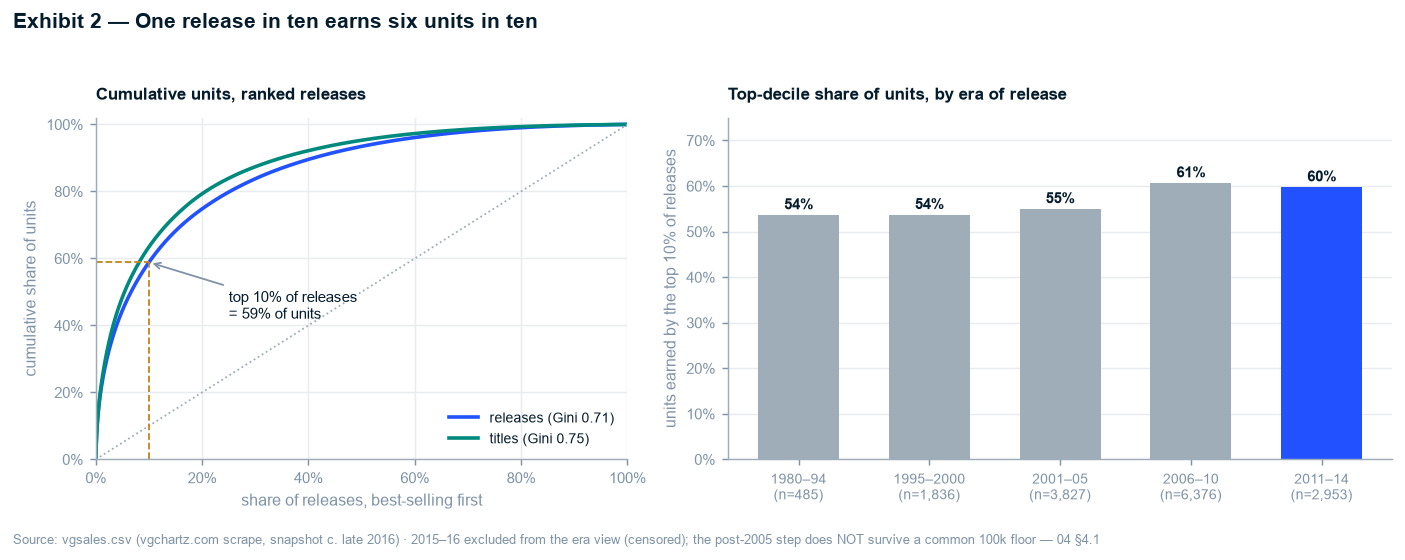

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 3.8), gridspec_kw={"width_ratios": [1, 1.25]})


def lorenz(x):
    s = np.sort(np.asarray(x, dtype=float))[::-1]
    return np.r_[0, np.arange(1, len(s) + 1) / len(s)], np.r_[0, np.cumsum(s) / s.sum()]


for x_, lab, col in [(df.Global_Sales, f"releases (Gini {row_g:.2f})", BLUE),
                     (titles.units, f"titles (Gini {title_g:.2f})", TEAL)]:
    a, b = lorenz(x_)
    ax1.plot(a, b, color=col, lw=2, label=lab)
ax1.plot([0, 1], [0, 1], color=GREY, lw=1, ls=":")
t10 = top_share(df.Global_Sales)
ax1.plot([0.10, 0.10], [0, t10], color=AMBER, lw=1, ls="--")
ax1.plot([0, 0.10], [t10, t10], color=AMBER, lw=1, ls="--")
ax1.annotate(f"top 10% of releases\n= {t10:.0%} of units", xy=(0.10, t10), xytext=(0.25, 0.42),
             fontsize=8.5, color=NAVY, arrowprops=dict(arrowstyle="->", color=SLATE, lw=1))
ax1.set_xlabel("share of releases, best-selling first")
ax1.set_ylabel("cumulative share of units")
ax1.xaxis.set_major_formatter(PCT); ax1.yaxis.set_major_formatter(PCT)
ax1.set_xlim(0, 1); ax1.set_ylim(0, 1.02)
ax1.legend(loc="lower right", fontsize=8)
ax1.grid(axis="x")
ax1.set_title("Cumulative units, ranked releases", fontsize=9.5)

xs = np.arange(len(era_conc))
cols = [GREY] * (len(era_conc) - 1) + [BLUE]
ax2.bar(xs, era_conc.top10, color=cols, width=0.62)
for i, v in enumerate(era_conc.top10):
    ax2.text(i, v + 0.012, f"{v:.0%}", ha="center", fontsize=8.5, color=NAVY, fontweight="bold")
ax2.set_xticks(xs, [f"{e}\n(n={n:,})" for e, n in zip(era_conc.index, era_conc.releases)], fontsize=8)
ax2.set_ylim(0, 0.75)
ax2.yaxis.set_major_formatter(PCT)
ax2.set_ylabel("units earned by the top 10% of releases")
ax2.set_title("Top-decile share of units, by era of release", fontsize=9.5)

suptitle(fig, "Exhibit 2 — One release in ten earns six units in ten")
finish(fig, "2015–16 excluded from the era view (censored); the post-2005 step does NOT survive a common 100k floor — 04 §4.1")
plt.tight_layout()
save(fig, "ex02_concentration.png")
plt.show()

In [7]:
kf_update(
    gini_rows=row_g, gini_titles=title_g,
    top10_title_share=top_share(titles.units), top1_title_share=top_share(titles.units, .01),
    p90_units=df.Global_Sales.quantile(.9), p99_units=df.Global_Sales.quantile(.99),
    era_top10=era_conc.top10.round(4).tolist(), era_gini=era_conc.gini.round(4).tolist(),
    era_median=era_conc["median"].tolist(), era_releases=era_conc.releases.tolist(), era_labels=list(era_conc.index),
)

  _key_figures.json <- gini_rows, gini_titles, top10_title_share, top1_title_share, p90_units, p99_units, era_top10, era_gini, era_median, era_releases, era_labels  (77 figures total)


**So What:** the median release sells 170,000 units; the 90th percentile sells over a million; the
99th percentile over five million. The top decile's share sat at 54–55% in every era to 2005 and
stepped up to 60–61% after — but `04` §4.1 shows that step is the catalogue getting deeper at the
bottom, not the hits getting bigger: above a common 100k floor it is not significant.
Measured by title rather than by game × platform the outcome is *more* unequal (Gini 0.76 vs 0.71),
because the biggest games also ship on the most platforms.

**Implication:** a slate cannot be planned on the average release — the mean (0.54 M) is three times
the median and is set by a handful of outliers. Slate economics must be planned on the *distribution*:
how many releases it takes to expect one hit.

## 3.3 Branch C — owners: who captures the value?

In [8]:
pub_era = []
for e, g in dt[dt.censored_flag == 0].groupby("era", observed=True):
    s = g[g.Publisher != "Unknown"].groupby("Publisher").Global_Sales.sum()
    s = s / s.sum()
    pub_era.append({"era": e, "top5_publisher_share": s.nlargest(5).sum(), "hhi": (s ** 2).sum() * 1e4,
                    "first_party_unit_share": g.loc[g.first_party == 1, "Global_Sales"].sum() / g.Global_Sales.sum(),
                    "first_party_release_share": g.first_party.mean()})
pub_era = pd.DataFrame(pub_era).set_index("era")
pub_era.index = relabel(pub_era.index)
print(pub_era.round(3).to_string())

fp = df[df.manufacturer.isin(["Nintendo", "Sony", "Microsoft", "Sega"])]
fp_tbl = (fp.groupby(["manufacturer", "first_party"])
            .agg(releases=("Name", "size"), median=("Global_Sales", "median"), hit_rate=("is_hit", "mean"))
            .unstack("first_party"))
print()
print(fp_tbl.round(3).to_string())
fp_all = df.groupby("first_party").agg(releases=("Name", "size"), units=("Global_Sales", "sum"),
                                       median=("Global_Sales", "median"), hit_rate=("is_hit", "mean"))
print()
print(fp_all.round(3).to_string())

           top5_publisher_share       hhi  first_party_unit_share  first_party_release_share
1980–94                   0.754  3274.542                   0.602                      0.289
1995–2000                 0.550   930.702                   0.402                      0.200
2001–05                   0.548   817.270                   0.267                      0.112
2006–10                   0.534   801.468                   0.283                      0.071
2011–14                   0.567   785.159                   0.228                      0.079

             releases      median        hit_rate       
first_party         0    1      0      1        0      1
manufacturer                                            
Microsoft        2143  159   0.20  0.510    0.131  0.333
Nintendo         5567  704   0.14  0.895    0.068  0.482
Sega              127  132   0.11  0.135    0.047  0.114
Sony             5945  701   0.18  0.340    0.128  0.224

             releases    units  median  h

### Exhibit 3 — Platform holders publish one release in ten and earn three units in ten — on every platform family

  saved reports/figures/ex03_first_party.png


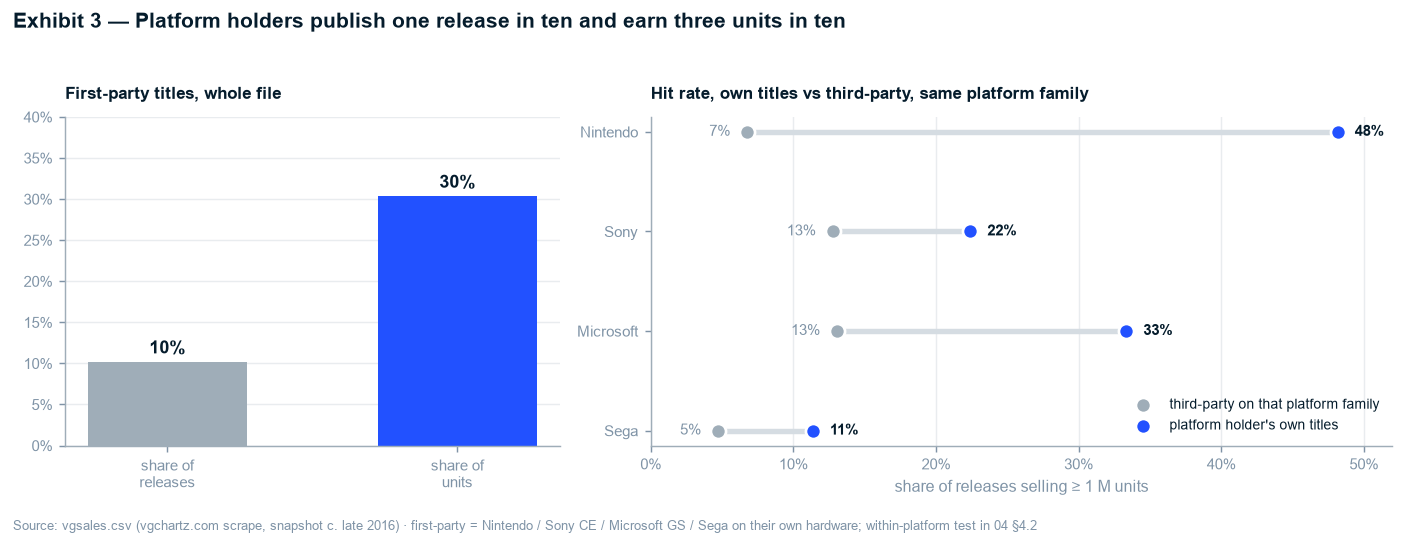

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 3.7), gridspec_kw={"width_ratios": [1, 1.5]})

rs, us = df.first_party.mean(), df.loc[df.first_party == 1, "Global_Sales"].sum() / df.Global_Sales.sum()
ax1.bar([0, 1], [rs, us], color=[GREY, BLUE], width=0.55)
for i, v in enumerate([rs, us]):
    ax1.text(i, v + 0.01, f"{v:.0%}", ha="center", fontsize=10, fontweight="bold", color=NAVY)
ax1.set_xticks([0, 1], ["share of\nreleases", "share of\nunits"])
ax1.set_ylim(0, 0.4)
ax1.yaxis.set_major_formatter(PCT)
ax1.set_title("First-party titles, whole file", fontsize=9.5)

order = ["Nintendo", "Sony", "Microsoft", "Sega"]
hr = fp.groupby(["manufacturer", "first_party"]).is_hit.mean().unstack().loc[order]
y = np.arange(len(order))[::-1]
for yi, m in zip(y, order):
    ax2.plot([hr.loc[m, 0], hr.loc[m, 1]], [yi, yi], color=LIGHT, lw=3, zorder=1)
ax2.scatter(hr[0], y, color=GREY, s=70, zorder=3, label="third-party on that platform family",
            edgecolor="white", linewidth=1.5)
ax2.scatter(hr[1], y, color=BLUE, s=70, zorder=3, label="platform holder's own titles",
            edgecolor="white", linewidth=1.5)
for yi, m in zip(y, order):
    ax2.text(hr.loc[m, 1] + 0.012, yi, f"{hr.loc[m, 1]:.0%}", va="center", fontsize=8.5, color=NAVY, fontweight="bold")
    ax2.text(hr.loc[m, 0] - 0.012, yi, f"{hr.loc[m, 0]:.0%}", va="center", ha="right", fontsize=8.5, color=SLATE)
ax2.set_yticks(y, order)
ax2.set_xlim(0, 0.52)
ax2.xaxis.set_major_formatter(PCT)
ax2.set_xlabel("share of releases selling ≥ 1 M units")
ax2.grid(axis="x"); ax2.grid(axis="y", visible=False)
ax2.legend(loc="lower right", fontsize=8)
ax2.set_title("Hit rate, own titles vs third-party, same platform family", fontsize=9.5)

suptitle(fig, "Exhibit 3 — Platform holders publish one release in ten and earn three units in ten")
finish(fig, "first-party = Nintendo / Sony CE / Microsoft GS / Sega on their own hardware; "
            "within-platform test in 04 §4.2")
plt.tight_layout()
save(fig, "ex03_first_party.png")
plt.show()

In [10]:
kf_update(
    fp_hit_rate=fp_all.loc[1, "hit_rate"], tp_hit_rate=fp_all.loc[0, "hit_rate"],
    fp_median=fp_all.loc[1, "median"], tp_median=fp_all.loc[0, "median"],
    fp_unit_share_by_era=pub_era.first_party_unit_share.round(4).tolist(),
    top5_pub_share_by_era=pub_era.top5_publisher_share.round(4).tolist(),
    hhi_by_era=pub_era.hhi.round(0).tolist(),
    fp_hit_rate_nintendo=hr.loc["Nintendo", 1], tp_hit_rate_nintendo=hr.loc["Nintendo", 0],
    fp_hit_rate_sony=hr.loc["Sony", 1], tp_hit_rate_sony=hr.loc["Sony", 0],
    fp_hit_rate_microsoft=hr.loc["Microsoft", 1], tp_hit_rate_microsoft=hr.loc["Microsoft", 0],
)

  _key_figures.json <- fp_hit_rate, tp_hit_rate, fp_median, tp_median, fp_unit_share_by_era, top5_pub_share_by_era, hhi_by_era, fp_hit_rate_nintendo, tp_hit_rate_nintendo, fp_hit_rate_sony, tp_hit_rate_sony, fp_hit_rate_microsoft, tp_hit_rate_microsoft  (90 figures total)


**So What:** a platform holder's own release is roughly three times as likely to sell a million as
a third-party release, and the gap holds on every platform family — so it is not an artifact of
Nintendo's catalogue alone. Meanwhile publisher concentration *outside* the first-party effect fell
sharply after the 1980s and has been flat since: the top five publishers' share sits near 55% in
every era since 1995.

**Implication:** for a third-party publisher, the relevant base rate is the **third-party** hit rate
(~10%), not the market-wide 12.5%; every slate-sizing figure in the report uses it. Whether the
premium survives controlling for platform and genre (first parties pick the best-selling platforms
and genres) is tested in `04` §4.2.

## 3.4 Branch D — regions: where is the value, and how different is taste?

In [11]:
reg_era = dt[dt.censored_flag == 0].groupby("era", observed=True)[REGIONS].sum()
reg_era = reg_era.div(reg_era.sum(axis=1), axis=0)
reg_era.columns = ["NA", "EU", "JP", "Other"]
reg_era.index = relabel(reg_era.index)
print(reg_era.round(3).to_string())

              NA     EU     JP  Other
1980–94    0.532  0.112  0.334  0.021
1995–2000  0.463  0.245  0.248  0.044
2001–05    0.535  0.274  0.107  0.084
2006–10    0.510  0.274  0.102  0.113
2011–14    0.431  0.340  0.121  0.109


### Exhibit 4 — Japan's share of units fell from a third to a ninth after 2000; Europe's tripled to a third

  saved reports/figures/ex04_region_mix.png


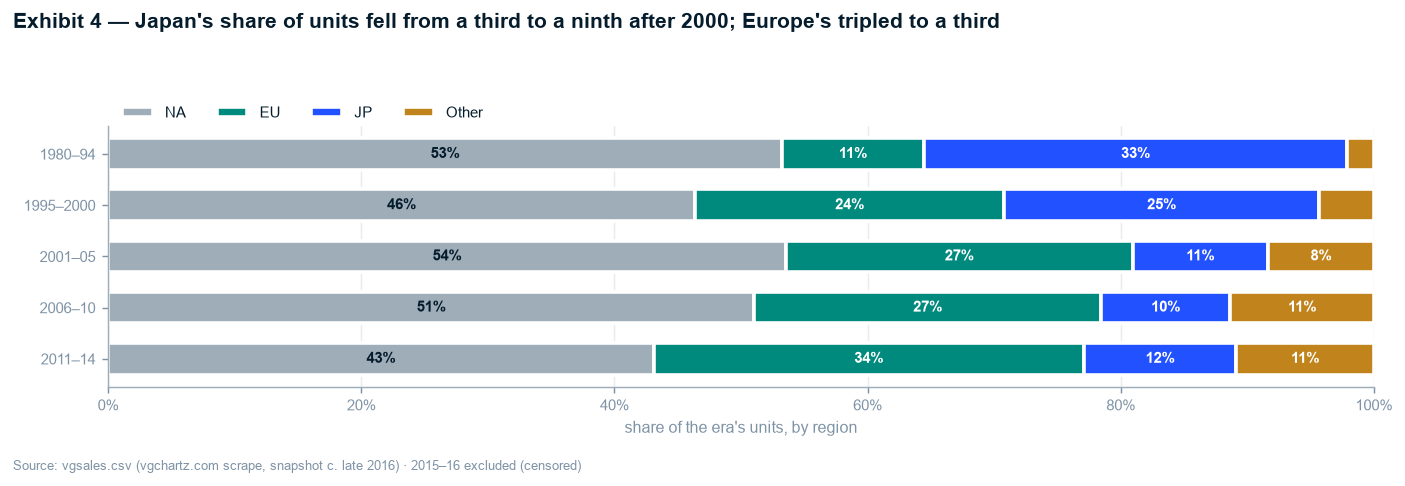

In [12]:
fig, ax = plt.subplots(figsize=(10.8, 3.2))
ys = np.arange(len(reg_era))[::-1]
left = np.zeros(len(reg_era))
for r in ["NA", "EU", "JP", "Other"]:
    v = reg_era[r].to_numpy()
    ax.barh(ys, v, left=left, color=REGION_COLORS[r], height=0.62, edgecolor="white", linewidth=2, label=r)
    for yi, l_, vv in zip(ys, left, v):
        if vv > 0.06:
            ax.text(l_ + vv / 2, yi, f"{vv:.0%}", ha="center", va="center", fontsize=8.5,
                    color="white" if r != "NA" else NAVY, fontweight="bold")
    left += v
ax.set_yticks(ys, reg_era.index)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PCT)
ax.grid(axis="y", visible=False); ax.grid(axis="x")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, 1.13), fontsize=8.5)
ax.set_xlabel("share of the era's units, by region")
suptitle(fig, "Exhibit 4 — Japan's share of units fell from a third to a ninth after 2000; Europe's tripled to a third", y=1.06)
finish(fig, "2015–16 excluded (censored)")
plt.tight_layout()
save(fig, "ex04_region_mix.png")
plt.show()

In [13]:
GENRE_ORDER = (dt.groupby("Genre", observed=True)[["JP_Sales", "Global_Sales"]].sum()
                 .eval("JP_Sales / Global_Sales").sort_values(ascending=False).index.tolist())
ERA4 = {"1980–94": "≤2000", "1995–2000": "≤2000", "2001–05": "2001–05", "2006–10": "2006–10", "2011–16": "2011–14"}
d4 = dt[dt.censored_flag == 0].assign(era4=lambda d: d.era.astype(str).map(ERA4))
gx = d4.groupby(["Genre", "era4"], observed=True)[REGIONS].sum()
jp = (gx.JP_Sales / gx[REGIONS].sum(axis=1)).unstack().loc[GENRE_ORDER, ["≤2000", "2001–05", "2006–10", "2011–14"]]
eu = (gx.EU_Sales / gx[REGIONS].sum(axis=1)).unstack().loc[GENRE_ORDER, ["≤2000", "2001–05", "2006–10", "2011–14"]]
all_jp = (dt.groupby("Genre", observed=True).JP_Sales.sum() / dt.groupby("Genre", observed=True)[REGIONS].sum().sum(axis=1)).loc[GENRE_ORDER]
print("JP share of each genre's units, by era"); print((jp * 100).round(1).to_string())
print("\nEU share of each genre's units, by era"); print((eu * 100).round(1).to_string())
n_eu_up = int((eu["2011–14"] > eu["2001–05"]).sum())
print(f"\ngenres whose EU share is higher in 2011–14 than 2001–05: {n_eu_up} of {len(eu)}")

JP share of each genre's units, by era
era4          ≤2000  2001–05  2006–10  2011–14
Genre                                         
Role-Playing   55.7     31.0     32.4     34.6
Strategy       38.4     30.4     17.3     21.9
Puzzle         31.7     24.2     11.6     25.6
Adventure      30.5     17.0     17.8     28.4
Fighting       30.1     12.7     13.2     19.5
Simulation     44.3     13.9      6.7     22.5
Platform       22.5      8.8     11.9     13.2
Misc           27.8     12.1     11.3     11.3
Sports         29.9      6.7      6.8      5.3
Action         14.1      7.0      6.7      8.6
Racing         16.5      5.5      3.5      6.7
Shooter        11.5      2.0      2.3      2.7

EU share of each genre's units, by era
era4          ≤2000  2001–05  2006–10  2011–14
Genre                                         
Role-Playing   16.1     22.7     17.8     24.1
Strategy       20.1     21.6     32.1     33.6
Puzzle         10.4     24.9     30.3     37.1
Adventure      27.4     27.7

### Exhibit 5 — Japan buys role-playing games and not shooters, and has done so in every era

  saved reports/figures/ex05_genre_region.png


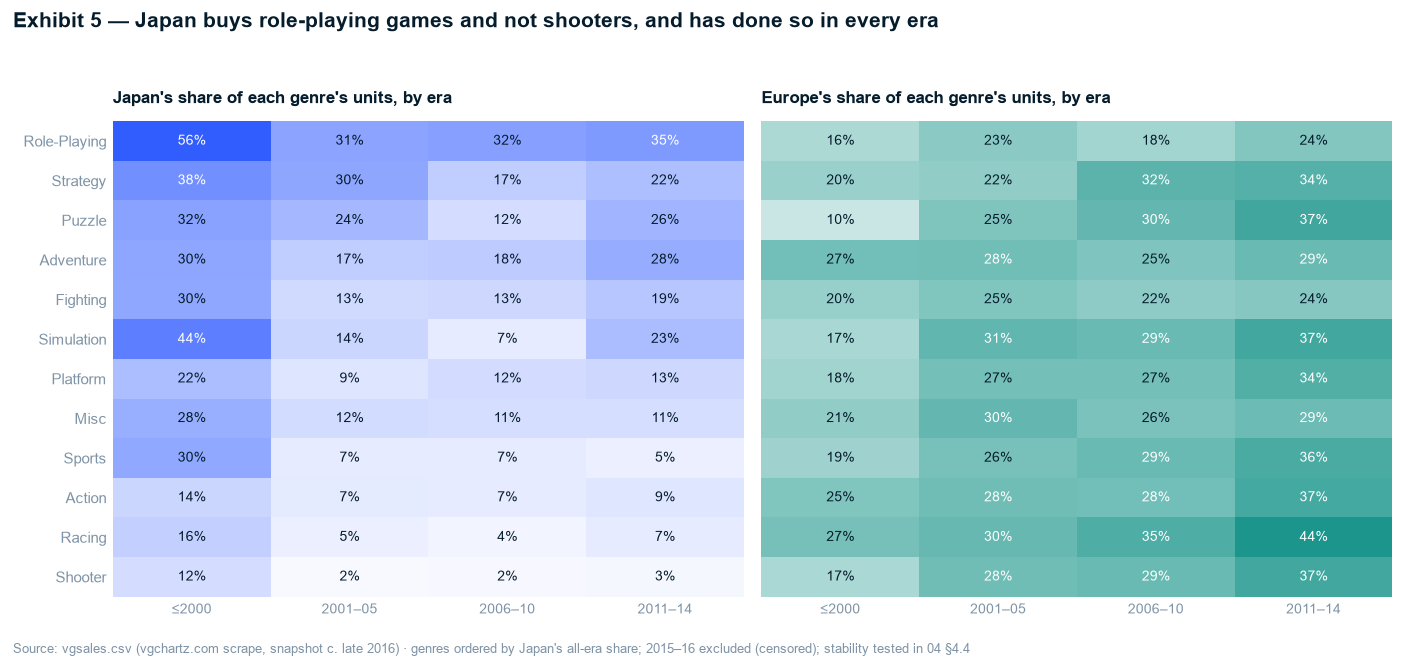

In [14]:
from matplotlib.colors import LinearSegmentedColormap

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.6), sharey=True)
for ax, mat, col, lab in [(ax1, jp, BLUE, "Japan"), (ax2, eu, TEAL, "Europe")]:
    cmap = LinearSegmentedColormap.from_list("seq", ["#FFFFFF", col])
    vmax = 0.6 if lab == "Japan" else 0.5
    ax.imshow(mat.to_numpy(), cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat.iat[i, j]
            ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if v > vmax * 0.55 else NAVY)
    ax.set_xticks(range(mat.shape[1]), mat.columns, fontsize=8)
    ax.set_yticks(range(mat.shape[0]), mat.index)
    ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.tick_params(length=0)
    ax.set_title(f"{lab}'s share of each genre's units, by era", fontsize=9.5)

suptitle(fig, "Exhibit 5 — Japan buys role-playing games and not shooters, and has done so in every era")
finish(fig, "genres ordered by Japan's all-era share; 2015–16 excluded (censored); stability tested in 04 §4.4")
plt.tight_layout()
save(fig, "ex05_genre_region.png")
plt.show()

In [15]:
kf_update(
    region_mix_eras=reg_era.index.astype(str).tolist(),
    jp_share_by_era=reg_era.JP.round(4).tolist(), eu_share_by_era=reg_era.EU.round(4).tolist(),
    na_share_by_era=reg_era.NA.round(4).tolist(),
    jp_share_rpg=all_jp.loc["Role-Playing"], jp_share_shooter=all_jp.loc["Shooter"],
    jp_share_racing=all_jp.loc["Racing"], jp_share_sports=all_jp.loc["Sports"],
    jp_share_strategy=all_jp.loc["Strategy"],
    jp_rpg_min_era=jp.loc["Role-Playing"].min(), jp_shooter_max_era=jp.loc["Shooter"].max(),
    eu_share_racing_2011=eu.loc["Racing", "2011–14"], n_genres_eu_up=n_eu_up,
)

  _key_figures.json <- region_mix_eras, jp_share_by_era, eu_share_by_era, na_share_by_era, jp_share_rpg, jp_share_shooter, jp_share_racing, jp_share_sports, jp_share_strategy, jp_rpg_min_era, jp_shooter_max_era, eu_share_racing_2011, n_genres_eu_up  (103 figures total)


**So What:** Japan's appetite is genre-specific and durable. Role-playing games take 38% of their
units from Japan across the file and never fall below 30% in any era; shooters never exceed 12% and
are at 2–3% since 2001. Europe's rise (Exhibit 4) is broad-based — 10 of 12 genres take a larger share
of their units from Europe in 2011–14 than in 2001–05, and the other two are flat.

**Implication:** a localisation budget is a genre decision before it is a market decision. Japanese
localisation and marketing earns its cost on RPGs, strategy and puzzle titles and almost never on
shooters, racing or sports; Europe is now a third of the market for nearly every genre. The formal
stability test (rank correlation across eras, with a permutation null) is `04` §4.4.

## 3.5 Branch E — products: does *what* you make separate winners?

In [16]:
ge = (df.groupby("Genre", observed=True)
        .agg(releases=("Name", "size"), units=("Global_Sales", "sum"), median=("Global_Sales", "median"),
             mean=("Global_Sales", "mean"), hit_rate=("is_hit", "mean"))
        .sort_values("hit_rate"))
ge["unit_share"] = ge.units / ge.units.sum()
print(ge.round(3).to_string())
print(f"\nhit-rate range across genres: {ge.hit_rate.min():.1%} – {ge.hit_rate.max():.1%}")
print(f"median range across genres  : {ge['median'].min():.2f} – {ge['median'].max():.2f} M")
qq = df.groupby("Genre", observed=True).Global_Sales.quantile([0.1, 0.9]).unstack()
ratio = qq[0.9] / qq[0.1]
print(f"p90 / p10 within genre      : {ratio.min():.0f}× – {ratio.max():.0f}× (median {ratio.median():.0f}×)")
print(f"best / worst genre median   : {ge['median'].max() / ge['median'].min():.1f}×")
print(f"best / worst genre hit rate : {ge.hit_rate.max() / ge.hit_rate.min():.1f}×")

              releases    units  median   mean  hit_rate  unit_share
Genre                                                               
Adventure         1286   239.04   0.060  0.186     0.033       0.027
Strategy           681   175.12   0.090  0.257     0.047       0.020
Puzzle             582   244.95   0.110  0.421     0.096       0.027
Misc              1739   809.96   0.160  0.466     0.099       0.091
Simulation         867   392.20   0.160  0.452     0.107       0.044
Action            3316  1751.18   0.190  0.528     0.128       0.196
Sports            2345  1330.92   0.220  0.568     0.129       0.149
Role-Playing      1488   927.37   0.185  0.623     0.136       0.104
Racing            1249   732.04   0.190  0.586     0.146       0.082
Fighting           848   448.91   0.210  0.529     0.146       0.050
Shooter           1309  1037.35   0.230  0.792     0.193       0.116
Platform           885   831.37   0.280  0.939     0.220       0.093

hit-rate range across genres: 3.3

### Exhibit 6 — Genre shifts the odds of a hit, but the spread inside every genre is wider than the gap between genres

  saved reports/figures/ex06_genre_economics.png


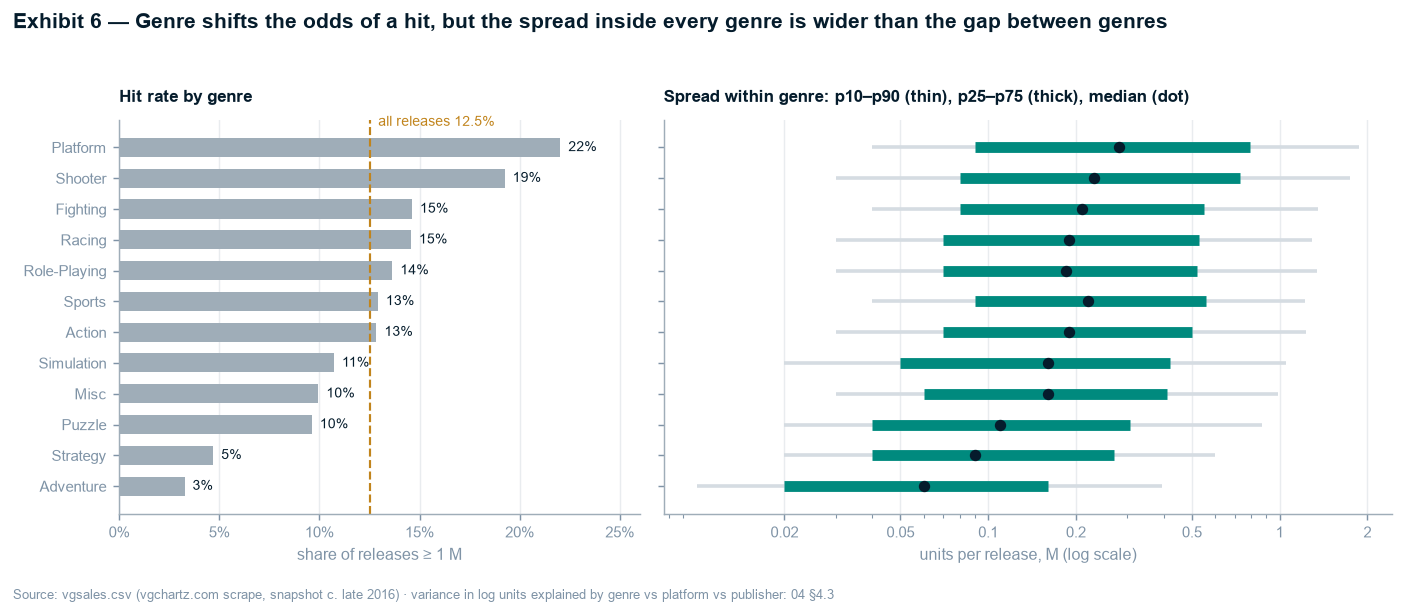

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.8, 4.2), sharey=True, gridspec_kw={"width_ratios": [1, 1.4]})
y = np.arange(len(ge))
ax1.barh(y, ge.hit_rate, color=GREY, height=0.62)
base = df.is_hit.mean()
ax1.axvline(base, color=AMBER, lw=1.2, ls="--")
ax1.text(base + 0.004, len(ge) - 0.4, f"all releases {base:.1%}", fontsize=8, color=AMBER, va="bottom")
for yi, v in zip(y, ge.hit_rate):
    ax1.text(v + 0.004, yi, f"{v:.0%}", va="center", fontsize=8, color=NAVY)
ax1.set_yticks(y, ge.index)
ax1.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax1.set_xlim(0, 0.26)
ax1.grid(axis="y", visible=False); ax1.grid(axis="x")
ax1.set_xlabel("share of releases ≥ 1 M")
ax1.set_title("Hit rate by genre", fontsize=9.5)

q = df.groupby("Genre", observed=True).Global_Sales.quantile([0.1, 0.25, 0.5, 0.75, 0.9]).unstack().loc[ge.index]
ax2.hlines(y, q[0.1], q[0.9], color=LIGHT, lw=2)
ax2.hlines(y, q[0.25], q[0.75], color=TEAL, lw=6)
ax2.scatter(q[0.5], y, color=NAVY, s=28, zorder=3, label="median")
ax2.set_xscale("log")
ax2.set_xticks([0.02, 0.05, 0.1, 0.2, 0.5, 1, 2], ["0.02", "0.05", "0.1", "0.2", "0.5", "1", "2"])
ax2.set_xlabel("units per release, M (log scale)")
ax2.grid(axis="y", visible=False); ax2.grid(axis="x")
ax2.set_title("Spread within genre: p10–p90 (thin), p25–p75 (thick), median (dot)", fontsize=9.5)

suptitle(fig, "Exhibit 6 — Genre shifts the odds of a hit, but the spread inside every genre is wider than the gap between genres")
finish(fig, "variance in log units explained by genre vs platform vs publisher: 04 §4.3")
plt.tight_layout()
save(fig, "ex06_genre_economics.png")
plt.show()

In [18]:
kf_update(
    genre_hit_min=ge.hit_rate.min(), genre_hit_max=ge.hit_rate.max(),
    genre_hit_min_name=ge.hit_rate.idxmin(), genre_hit_max_name=ge.hit_rate.idxmax(),
    genre_median_min=ge["median"].min(), genre_median_max=ge["median"].max(),
    platform_genre_mean=ge.loc["Platform", "mean"], platform_genre_median=ge.loc["Platform", "median"],
    within_genre_p90_p10_min=ratio.min(), within_genre_p90_p10_max=ratio.max(),
    genre_median_ratio=ge["median"].max() / ge["median"].min(),
)

  _key_figures.json <- genre_hit_min, genre_hit_max, genre_hit_min_name, genre_hit_max_name, genre_median_min, genre_median_max, platform_genre_mean, platform_genre_median, within_genre_p90_p10_min, within_genre_p90_p10_max, genre_median_ratio  (114 figures total)


**So What:** genre does shift the odds — Platform games hit 22% of the time, Adventure games 3% — and
the best genre's median release sells about 4.7× the worst's. But the *within*-genre spread is wider
still: in every genre the 90th-percentile release sells 30–58× the 10th. Knowing the genre narrows a
release's outcome far less than it appears to from a hit-rate league table. The Platform genre's mean (0.94 M)
is more than three times its median (0.28 M) — a few Mario titles, not a reliable genre.

**Implication:** "pick the right genre" is a weak lever. `04` §4.3 measures exactly how weak, against
platform and publisher, with cross-validation so a 578-level publisher variable cannot win by
overfitting.

---

### Updated ghost deck (after EDA)

| Part | Anticipated action title | Status after EDA |
|---|---|---|
| I · The record | The post-2010 slump is two retiring platforms and censored years | **Confirmed** — DS + Wii dominate the lost releases; hit rate per release *rose* |
| II · Concentration | 10% of releases earn ~60% of units, rising | Level confirmed; **the "rising" part is tested against catalogue depth** (04 §4.1 — it fails) |
| II · Owners | Platform holders out-sell third parties ~3×, on every platform | Confirmed descriptively; **within-platform test needed** (04 §4.2) |
| III · Regions | Japan's taste map is stable | Confirmed descriptively; **formal stability test** (04 §4.4) |
| IV · Products → Foreseeability | *What* you make matters less than *who* makes it | New hypothesis from Exhibit 6 → **variance decomposition** (04 §4.3) and the model (05) |

## Stage 3 — Gate Checklist

- [x] Automated profile replaced by `01`'s written contract + re-derivation (16k × 11 is small enough to profile by hand, column by column)
- [x] Each Stage 0 hypothesis (branches A–E) has at least one analysis; F is `05`
- [x] Key distributions and relationships visualised and annotated — 6 exhibits
- [x] All chart titles are Action Titles · [x] every exhibit has a So What and an Implication
- [x] Ghost deck updated (table above)
- [x] Data issues found in EDA logged: right-censoring of 2015–16 → excluded from era views (fed back into `02` as `censored_flag`)